# Week 2: Checking the embedding setup before measuring knowledge extent

Downloaded 10,000 random journal articles per year, 2001–2024 (`src/openalex_pool.py`). Before embedding all 240,000 papers, this notebook runs two checks on the measuring instrument:

1. **Truncation.** How many title + abstract inputs are longer than 288 tokens (the cutoff Hao et al. used) or 512 tokens (the model's maximum), and does that share change over time?
2. **Model check.** Does embedding distance track citation links between papers, and does it work as well for early papers as for recent ones?
3. How does it perform for clustering? Do clusters overlap with OpenAlex's subtopics?

## Literature Review

This week's method, representing text as embeddings and measuring semantic similarity as the distance between them, is the measuring instrument for my project. I reviewed three recent papers that use embeddings to measure meaning and used them to decide how to set up and check that instrument.

Hao et al. (2026) embed 41.3 million natural-science papers with SPECTER2 and measure the *knowledge extent* (KE) of a group of papers as the largest Euclidean distance between a paper's vector and the mean vector (centroid) of a fixed-size sample. They draw 1,000 papers, repeat the draw 1,000 times, and compare medians. Papers that use AI have about 4.6% lower median KE than other papers, which they read as AI-augmented research covering a narrower part of the semantic space. My project applies this measure to one field over time, so I follow their setup wherever my question allows: SPECTER2 with the proximity adapter, the title and abstract joined by a separator token, the first-token ([CLS]) vector, raw (not normalized) vectors, Euclidean distance, and 1,000 × 1,000 draws. One choice I did not copy is their 288-token input cutoff. Because I compare years rather than groups of papers, a cutoff that removes more text from later, longer abstracts would change the instrument over time, so Section 1 counts how many inputs each cutoff truncates in each year.

Singh et al. (2023) introduce SciRepEval, a benchmark of 24 tasks for scientific document embeddings, and show that a single embedding per paper does not work equally well for classification, regression, ranking and search. Their solution, released as SPECTER2, learns a separate embedding for each task format through small "adapter" layers. This is why I use the proximity adapter: it is the version meant for finding similar papers, which is what a distance-based measure needs. It also explains a limitation of my model check in Section 2. The SPECTER models learn similarity from citation links (Cohan et al., 2020), so a test of whether a paper sits closer to a work it cites than to a random paper favors SPECTER2. I therefore read the check mainly as evidence that the model works as well for early papers as for recent ones, rather than as a ranking of models.

Zhu (2026) re-examines an earlier finding that words for "unintelligence" (such as "stupid") became more male-associated in twentieth-century American texts. Zhu argues that a distance in embedding space can correspond to many cultural meanings, so moving closer to the "male" pole cannot be read directly as a stereotype about men. Checking the embedding result against direct co-occurrence with gender words, and tracing which contexts drive the shift with an embedding approximation method (ALC) and close reading, Zhu finds that the change reflects a harsher tone in the surrounding language. The same caution applies to KE: a maximum distance can grow because research spreads to new topics, but also because of writing style, language, or non-research text. Using clustering and its respective composition-standardized KE, I hope to represent the change in KE attributed to changes in topic distribution and shifts in semantic space occupied by topics. Similar to Zhu, I aim to find the source of change in the embedding geometry rather than only to report it.

The earlier class readings support the same steps. Kozlowski, Taddy and Evans (2019) and Garg et al. (2018) track cultural change by comparing embeddings across decades, which works only if the instrument measures the same thing in every period. I use one fixed pretrained model for all years and check that its accuracy does not drift between 2001–2008 and 2017–2024. Caliskan, Bryson and Narayanan (2017) show that embeddings absorb the associations in their training text. SPECTER2's sense of "similar" therefore reflects how scientists cite each other, which is a theoretical choice about what similarity means rather than a neutral one.

**References**

- Caliskan, A., Bryson, J. J., & Narayanan, A. (2017). Semantics derived automatically from language corpora contain human-like biases. *Science*, 356, 183–186.
- Cohan, A., Feldman, S., Beltagy, I., Downey, D., & Weld, D. S. (2020). SPECTER: Document-level representation learning using citation-informed transformers. *Proceedings of ACL 2020*. https://doi.org/10.18653/v1/2020.acl-main.207
- Garg, N., Schiebinger, L., Jurafsky, D., & Zou, J. (2018). Word embeddings quantify 100 years of gender and ethnic stereotypes. *PNAS*, 115, E3635–E3644.
- Hao, Q., Xu, F., Li, Y., & Evans, J. (2026). Artificial intelligence tools expand scientists' impact but contract science's focus. *Nature*, 649(8099), 1237–1243. https://doi.org/10.1038/s41586-025-09922-y
- Kozlowski, A. C., Taddy, M., & Evans, J. A. (2019). The geometry of culture: Analyzing the meanings of class through word embeddings. *American Sociological Review*, 84(5).
- Singh, A., D'Arcy, M., Cohan, A., Downey, D., & Feldman, S. (2023). SciRepEval: A multi-format benchmark for scientific document representations. *Proceedings of EMNLP 2023*. https://doi.org/10.18653/v1/2023.emnlp-main.338
- Zhu, Y. (2026). Explaining gendered language through embedding approximation: How "stupid" became a man's word. *Social Forces*, soag103. https://doi.org/10.1093/sf/soag103

### Short Literature Review

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

from api_test import extract   # OpenAlex requests with saved checkpoints
from src import embeddings     # the embedding setup shared with the full run

POOL = Path("data/pool/psychology_field32/pool.parquet")
VALIDATION = Path("data/validation/citation_pairs")
TABLES, FIGURES = Path("outputs/tables"), Path("outputs/figures")
for folder in (VALIDATION, TABLES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 20261026  # pilot sample, reference choice, and bootstrap

# chart style: thin lines, recessive grid, text in ink colors (not series colors)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

def style_axes(ax):
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED)

### Load the pools

Every paper is embedded, so the truncation count uses all 240,000. At the KE step, papers with a missing title and papers whose abstract text is shared with another paper (publisher boilerplate such as "No abstract available", and duplicate records) are dropped. The model check uses only papers that would enter KE.

In [2]:
pool = pd.read_parquet(POOL)
missing_title = pool["title"].fillna("").str.strip() == ""
shared_abstract = pool["abstract"].str.lower().str.strip().duplicated(keep=False)
pool["ke_eligible"] = ~(missing_title | shared_abstract)

print(f"{len(pool):,} papers, {pool['publication_year'].min()}–{pool['publication_year'].max()}")
print(f"Missing title: {missing_title.sum():,} | abstract shared with another paper: {shared_abstract.sum():,} "
      f"| eligible for KE: {pool['ke_eligible'].sum():,}")

240,000 papers, 2001–2024
Missing title: 67 | abstract shared with another paper: 2,776 | eligible for KE: 237,157


In [12]:
pool.head()

,openalex_id,publication_year,doi,title,abstract,abstract_chars,publication_date,type,language,primary_topic,...,primary_field_id,source_id,source_name,source_issn_l,source_type,cited_by_count,source_seed,sample_position,ke_eligible,tokens
0,https://openalex.org/W1965033370,2001,https://doi.org/10.1080/07448480109596009,The Prevalence of Elevated Psychological Distr...,For a study of elevated psychological distress...,562,2001-09-01,article,en,Student Stress and Coping,...,https://openalex.org/fields/32,https://openalex.org/S70371499,Journal of American College Health,0164-4300,journal,406,1,0,True,114
1,https://openalex.org/W2312438637,2001,https://doi.org/10.4097/kjae.2001.40.4.435,Effects of Sensory Information on Preoperative...,Background: Preoperative anxiety is described ...,1584,2001-01-01,article,en,Music Therapy and Health,...,https://openalex.org/fields/32,https://openalex.org/S4210221379,Korean Journal of Anesthesiology,0302-5780,journal,6,1,1,True,297
2,https://openalex.org/W1588229439,2001,https://doi.org/10.1080/00455091.2001.10717580,The Charitable Perspective: Forgiveness and To...,'May one be pardon’ d and retain the offence?’...,1131,2001-12-01,article,en,Forgiveness and Related Behaviors,...,https://openalex.org/fields/32,https://openalex.org/S41191225,Canadian Journal of Philosophy,0045-5091,journal,24,1,2,True,272
3,https://openalex.org/W2182849423,2001,https://doi.org/10.1192/pb.25.4.126,Reform of the Mental Health Act 1983: the Gree...,The profession awaits the Government's White P...,274,2001-04-01,article,en,Healthcare Decision-Making and Restraints,...,https://openalex.org/fields/32,https://openalex.org/S68436342,Psychiatric Bulletin,0955-6036,journal,12,1,3,True,77
4,https://openalex.org/W2322013090,2001,https://doi.org/10.1300/j085v12n01_05,Combining the Written and Verbal Media of Lang...,In this article particular focus is given to d...,570,2001-01-01,article,en,"Counseling, Therapy, and Family Dynamics",...,https://openalex.org/fields/32,https://openalex.org/S145138831,International Journal of Systemic Therapy,0897-5353,journal,3,1,4,True,116


## 1. Truncation: how many inputs are longer than the cutoff?

SPECTER2 reads the title and abstract as one input, `title [SEP] abstract`, split into tokens (words and word pieces). Anything past the cutoff is ignored, usually the results and conclusions at the end of the abstract. Hao et al. cut inputs at 288 tokens, however the model accepts up to 512.

A fixed cutoff is only harmless if it removes about the same share of text every year. If abstracts get longer over time, the same cutoff removes more of recent abstracts, so the measuring instrument changes across years. The cell below counts each input's tokens without truncating (including the two special tokens the model adds).

In [3]:
tokenizer = AutoTokenizer.from_pretrained("allenai/specter2_base")
texts = [embeddings.input_text(t, a, tokenizer.sep_token) for t, a in zip(pool["title"], pool["abstract"])]

start = time.time()
pool["tokens"] = embeddings.token_counts(tokenizer, texts)
print(f"Counted tokens for {len(texts):,} inputs in {time.time() - start:.0f} s")

truncation = pool.groupby("publication_year").agg(
    median_tokens=("tokens", "median"),
    over_288=("tokens", lambda n: (n > 288).mean()),
    over_512=("tokens", lambda n: (n > 512).mean()),
)
truncation.to_csv(TABLES / "truncation_by_year.csv")
truncation.style.format({"median_tokens": "{:.0f}", "over_288": "{:.1%}", "over_512": "{:.1%}"})

Counted tokens for 240,000 inputs in 47 s


,median_tokens,over_288,over_512
publication_year,,,
2001,186,17.9%,5.2%
2002,188,17.8%,5.0%
2003,186,17.8%,4.6%
2004,188,18.8%,4.6%
2005,189,18.9%,4.9%
2006,191,20.0%,5.1%
2007,190,20.1%,4.8%
2008,191,19.0%,4.3%
2009,194,20.1%,4.4%


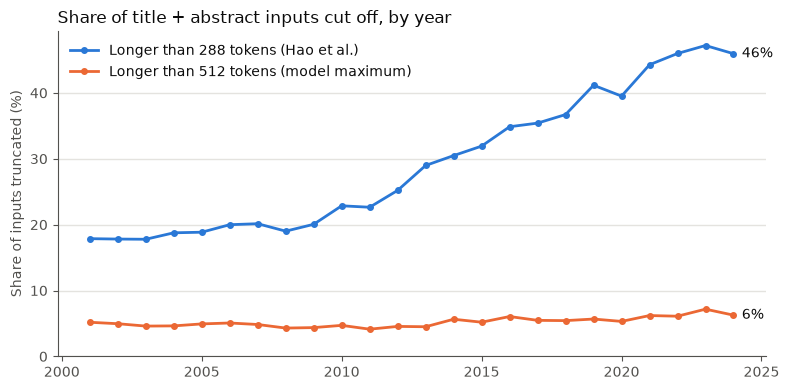

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
series = [("over_288", "Longer than 288 tokens (Hao et al.)"), ("over_512", "Longer than 512 tokens (model maximum)")]
for (column, label), color in zip(series, COLORS):
    ax.plot(truncation.index, truncation[column] * 100, color=color, linewidth=2,
            marker="o", markersize=4, label=label)
    ax.annotate(f"{truncation[column].iloc[-1]:.0%}", (truncation.index[-1], truncation[column].iloc[-1] * 100),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK)
ax.set_ylim(bottom=0)
ax.set_ylabel("Share of inputs truncated (%)", color=MUTED)
ax.set_title("Share of title + abstract inputs cut off, by year", color=INK, loc="left")
ax.legend(frameon=False, labelcolor=INK)
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "truncation_by_year.png", dpi=200)
plt.show()

**Result.** The median input grows from 186 tokens in 2001 to 278 in 2024. At Hao et al.'s 288-token cutoff, the share of inputs that get cut off rises from 18% in 2001 to 46% in 2024, so the same cutoff would ignore more of each abstract in later years and the measuring instrument would change over the period. At 512 tokens, 4–7% of inputs are cut off in every year (5.2% in 2001, 6.3% in 2024).

**Choice: truncate at 512 tokens**

## 2. Model check: does embedding distance track citation links?

When paper A cites paper B, the two are usually on related topics. A model whose distances mean "related research" should place A closer to B than to a random paper from the same year. 

Procedure:

1. Draw 100 KE-eligible papers per year (2,400 papers).
2. Look up each paper's reference list in OpenAlex, shuffle it (seeded), and keep the first cited work that has a title and an abstract (checking up to 5 candidates per paper).
3. Embed the pilot papers and their cited works with each candidate model. All three use the same input format, 512-token cutoff, and embedding vector (`src/embeddings.py`).
4. For each pilot paper, compare its distance to its cited work with its distances to the 99 other pilot papers from the same year. The paper's score is the share of those 99 that are farther away than the cited work. A model's **AUC** is the average score: 0.5 means distance says nothing about citation (50% of cited papers are closer in Euclidean space than random papers), and 1.0 means the cited work is always closer than every random paper.

Candidate models: **SPECTER2 with the proximity adapter** (the provisional main model, as in Hao et al.), **SPECTER2 base** without the adapter, and **bge-base-en-v1.5**, a general-purpose English embedding model that also reads 512 tokens.

A limitation is that SPECTER2 was trained on citation links, so it has a home advantage on this test. The test is strongest for the question "does the model work as well in 2001 as in 2024?" and weaker for "which model is best?". Another limitation is that citations are not always topical (a paper may cite a statistics method), so even a good model scores well below 1.0.

### Step 1: pilot sample

In [16]:
pilot = (pool[pool["ke_eligible"]]
         .groupby("publication_year", group_keys=False)
         .sample(n=100, random_state=SEED)
         .reset_index(drop=True))
print(f"Pilot: {len(pilot):,} papers, {pilot.groupby('publication_year').size().min()} per year")

Pilot: 2,400 papers, 100 per year


### Step 2: reference lists and cited works

OpenAlex returns up to 100 works per ID lookup, so this took 106 requests (24 for the reference lists and 82 for the cited works). Each response is saved under `data/validation/citation_pairs/raw/` with its request URL, so re-running the notebook makes no new requests.

In [22]:
def check_lookup(payload):
    if not isinstance(payload.get("results"), list) or len(payload["results"]) > 100:
        raise RuntimeError("OpenAlex returned an invalid lookup page")

def lookup(ids, select, name):
    """Fetch works by OpenAlex ID, 100 per request, saving every response."""
    works = {}
    for page, start in enumerate(range(0, len(ids), 100)):
        batch = [work_id.rsplit("/", 1)[-1] for work_id in ids[start:start + 100]]
        url = extract.request_url({"filter": "openalex_id:" + "|".join(batch), "per_page": 100, "select": select})
        record = extract.checkpoint_request(VALIDATION / "raw" / f"{name}_{page:04d}.json", url, check_lookup)
        works.update({work["id"]: work for work in record["payload"]["results"]})
    return works

references = lookup(pilot["openalex_id"].tolist(), "id,referenced_works", "references")
pilot["n_references"] = [len(references.get(i, {}).get("referenced_works") or []) for i in pilot["openalex_id"]]
print(f"Reference lists returned for {len(references):,} of {len(pilot):,} pilot papers; "
      f"{(pilot['n_references'] > 0).mean():.1%} list at least one reference")

Reference lists returned for 2,400 of 2,400 pilot papers; 71.5% list at least one reference


In [24]:
rng = np.random.default_rng(SEED)
candidates = {}
for work_id in pilot["openalex_id"]:
    refs = list(references.get(work_id, {}).get("referenced_works") or [])
    rng.shuffle(refs)
    candidates[work_id] = refs[:5]

cited = lookup(sorted({ref for refs in candidates.values() for ref in refs}),
               "id,title,abstract_inverted_index,publication_year", "cited")

def usable(work):
    return bool(work and (work.get("title") or "").strip() and work.get("abstract_inverted_index"))

cited_ids = [next((ref for ref in candidates[w] if usable(cited.get(ref))), None) for w in pilot["openalex_id"]]
pilot["cited_id"] = cited_ids
pilot["cited_title"] = [cited[r]["title"] if r else None for r in cited_ids]
pilot["cited_abstract"] = [extract.reconstruct_abstract(cited[r]["abstract_inverted_index"]) if r else None
                           for r in cited_ids]

has_pair = pilot["cited_id"].notna().to_numpy()
print(f"Pilot papers with a usable cited work: {has_pair.sum():,} of {len(pilot):,}")
coverage = pilot.assign(with_cited_work=has_pair).groupby("publication_year")["with_cited_work"].mean()
coverage.to_frame().T.style.format("{:.0%}")

Pilot papers with a usable cited work: 1,676 of 2,400


publication_year,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
with_cited_work,69%,65%,65%,66%,66%,71%,69%,63%,65%,66%,71%,66%,74%,74%,81%,76%,74%,81%,70%,62%,74%,74%,67%,67%


### Step 3: embed with each model

Vectors are saved under `data/validation/citation_pairs/`, so a re-run loads them instead of embedding again.

In [25]:
import gc
import torch

pilot_ids = pilot["openalex_id"].to_numpy(dtype=str)
vectors = {}
for name in embeddings.MODELS:
    path = VALIDATION / f"vectors_{name}.npz"
    if path.exists() and np.array_equal(np.load(path)["pilot_ids"], pilot_ids):
        saved = np.load(path)
        vectors[name], info = (saved["pilot"], saved["cited"]), json.loads(str(saved["info"]))
        print(f"{name}: loaded saved vectors (revision {info['revision'][:8]})")
        continue
    model, tok, info = embeddings.load(name)
    pilot_texts = [embeddings.input_text(t, a, tok.sep_token) for t, a in zip(pilot["title"], pilot["abstract"])]
    pairs = pilot[has_pair]
    cited_texts = [embeddings.input_text(t, a, tok.sep_token) for t, a in zip(pairs["cited_title"], pairs["cited_abstract"])]
    pilot_vectors = embeddings.encode(model, tok, pilot_texts)
    cited_vectors = np.full_like(pilot_vectors, np.nan)
    cited_vectors[has_pair] = embeddings.encode(model, tok, cited_texts)
    np.savez(path, pilot=pilot_vectors, cited=cited_vectors, pilot_ids=pilot_ids,
             info=json.dumps(info))
    vectors[name] = (pilot_vectors, cited_vectors)
    print(f"{name}: revision {info['revision'][:8]}, adapter {info['adapter']} "
          f"({(info['adapter_revision'] or '-')[:8]}), device {info['device']}")
    del model
    gc.collect()
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()

specter2_proximity: loaded saved vectors (revision 3447645e)
specter2_base: loaded saved vectors (revision 3447645e)
bge_base: loaded saved vectors (revision a5beb1e3)


In [ ]:
print(vectors.keys())
print(vectors["specter2_proximity"][0].shape) # pilot papers (2400 papers, each with a 768 dimension vector embedding)


dict_keys(['specter2_proximity', 'specter2_base', 'bge_base'])
(2400, 768)


### Step 4: score each model

Main metric: Euclidean distance on the raw vectors, which is what KE uses. Cosine distance (Euclidean distance after scaling every vector to length 1) is shown as well, because KE on normalized vectors is the planned robustness check. The interval for "late − early" comes from resampling pilot papers (2,000 bootstrap draws); it describes sampling noise in this pilot only.

In [28]:
def paper_scores(pilot_vectors, cited_vectors, years, normalize=False):
    """Per pilot paper: share of the other same-year pilot papers that are farther away than its cited work."""
    if normalize:
        pilot_vectors = pilot_vectors / np.linalg.norm(pilot_vectors, axis=1, keepdims=True)
        cited_vectors = cited_vectors / np.linalg.norm(cited_vectors, axis=1, keepdims=True)
    scores = np.full(len(years), np.nan)
    for year in np.unique(years):
        rows = np.flatnonzero(years == year)
        group = pilot_vectors[rows]
        to_others = np.linalg.norm(group[:, None, :] - group[None, :, :], axis=2)
        to_cited = np.linalg.norm(group - cited_vectors[rows], axis=1)  # NaN if no cited work
        farther = (to_others > to_cited[:, None]) + 0.5 * (to_others == to_cited[:, None])
        np.fill_diagonal(farther, 0)
        scores[rows] = np.where(np.isnan(to_cited), np.nan, farther.sum(axis=1) / (len(rows) - 1))
    return scores

years = pilot["publication_year"].to_numpy()
period = np.select([years <= 2008, years >= 2017], ["2001–2008", "2017–2024"], "2009–2016")
boot = np.random.default_rng(SEED)
rows, blocks = [], {}
for name, (pilot_vectors, cited_vectors) in vectors.items():
    for distance, normalize in (("Euclidean, raw", False), ("cosine", True)):
        scores = paper_scores(pilot_vectors, cited_vectors, years, normalize)
        early, late = scores[has_pair & (period == "2001–2008")], scores[has_pair & (period == "2017–2024")]
        gaps = [boot.choice(late, late.size).mean() - boot.choice(early, early.size).mean() for _ in range(2000)]
        rows.append({"model": name, "distance": distance, "AUC, all years": np.nanmean(scores),
                     **{p: np.nanmean(scores[period == p]) for p in ("2001–2008", "2009–2016", "2017–2024")},
                     "late − early": late.mean() - early.mean(),
                     "95% interval": f"[{np.percentile(gaps, 2.5):+.3f}, {np.percentile(gaps, 97.5):+.3f}]"})
        if not normalize:
            blocks[name] = pd.Series(scores).groupby(2002 + (years - 2001) // 3 * 3).mean()

results = pd.DataFrame(rows)
results.to_csv(TABLES / "citation_pair_auc.csv", index=False)
results.style.format({c: "{:.3f}" for c in ["AUC, all years", "2001–2008", "2009–2016", "2017–2024"]}
                     | {"late − early": "{:+.3f}"}).hide(axis="index")

model,distance,"AUC, all years",2001–2008,2009–2016,2017–2024,late − early,95% interval
specter2_proximity,"Euclidean, raw",0.958,0.958,0.962,0.952,-0.006,"[-0.020, +0.008]"
specter2_proximity,cosine,0.958,0.958,0.963,0.952,-0.006,"[-0.020, +0.007]"
specter2_base,"Euclidean, raw",0.952,0.957,0.956,0.942,-0.015,"[-0.029, -0.001]"
specter2_base,cosine,0.952,0.957,0.957,0.942,-0.015,"[-0.028, -0.001]"
bge_base,"Euclidean, raw",0.947,0.950,0.947,0.943,-0.007,"[-0.024, +0.010]"
bge_base,cosine,0.947,0.952,0.946,0.944,-0.008,"[-0.024, +0.008]"


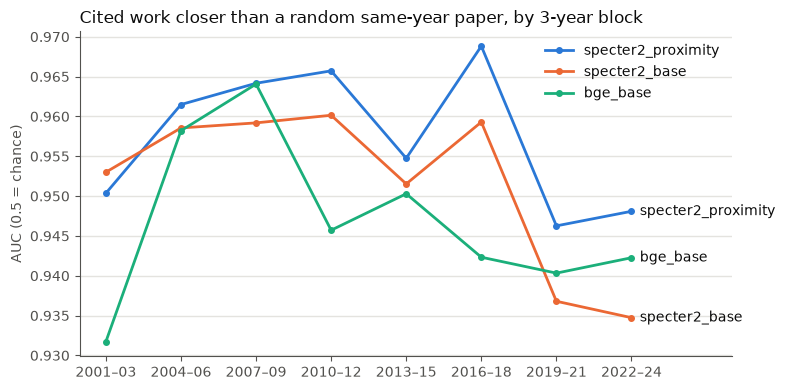

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for (name, series), color in zip(blocks.items(), COLORS):
    ax.plot(series.index, series.values, color=color, linewidth=2, marker="o", markersize=4, label=name)
    ax.annotate(name, (series.index[-1], series.values[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK)
ax.set_xticks(series.index, [f"{y - 1}–{str(y + 1)[2:]}" for y in series.index])
ax.set_ylabel("AUC (0.5 = chance)", color=MUTED)
ax.set_title("Cited work closer than a random same-year paper, by 3-year block", color=INK, loc="left")
ax.legend(frameon=False, labelcolor=INK, loc="upper right")
ax.set_xlim(right=series.index[-1] + 4)
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "citation_pair_auc_by_block.png", dpi=200)
plt.show()

### Three example pairs (SPECTER2 proximity, Euclidean distance)

Each row shows a 2024 pilot paper, the work it cites, and a random pilot paper from the same year, with the distances from the pilot paper.

In [12]:
pilot_vectors, cited_vectors = vectors["specter2_proximity"]
example_rng = np.random.default_rng(SEED)
examples = []
for i in example_rng.choice(np.flatnonzero(has_pair & (years == 2024)), size=3, replace=False):
    j = example_rng.choice(np.flatnonzero((years == 2024) & (np.arange(len(years)) != i)))
    examples.append({"pilot paper": pilot.at[i, "title"], "cited work": pilot.at[i, "cited_title"],
                     "distance to cited": np.linalg.norm(pilot_vectors[i] - cited_vectors[i]),
                     "random paper": pilot.at[j, "title"],
                     "distance to random": np.linalg.norm(pilot_vectors[i] - pilot_vectors[j])})
pd.DataFrame(examples).style.format({"distance to cited": "{:.1f}", "distance to random": "{:.1f}"}).hide(axis="index")

pilot paper,cited work,distance to cited,random paper,distance to random
The effect of textual and textual-pictorial glosses on incidental vocabulary learning in mobile-assisted listening,The Effects of Glosses on Incidental Vocabulary Acquisition in Reading,7.7,Eating Disorders in Sexual and Gender Minority Adolescents,13.9
Prolonged grief disorder in ICD-11 and DSM-5-TR: differences in prevalence and diagnostic criteria,Evidence of the clinical utility of a prolonged grief disorder diagnosis,6.4,Developing a Systematic Knowledge-Based Assessment of Vocabulary Learning Strategies,14.7
Measuring accumulation: Constructing a tool for evaluating cumulative harm in children engaged with an intensive family support service,Addressing cumulative harm: responding to chronic child maltreatment in the context of an intensive family support service,5.9,The influence of shared leadership on taking charge behavior: Dual perspective of cognition–affection,12.4


**Result.** About 70% of pilot papers (1,676 of 2,400) have a cited work with a title and abstract in OpenAlex; most of the rest list no references at all. The share varies between 62% and 81% by year with no trend, so early and late years are scored on similar subsets.

All three models place a paper's cited work closer than a random same-year Psychology paper about 95% of the time (AUC 0.947–0.958), far above chance (0.5):

- **SPECTER2 proximity** scores highest (0.958) and is stable over time: 0.958 in 2001–2008 and 0.952 in 2017–2024, a difference of −0.006 (interval −0.020 to +0.008).
- **SPECTER2 base** scores slightly lower and loses a little more over time (−0.015, interval −0.029 to −0.001).
- **bge-base** scores 0.947 and is also stable (−0.007, interval −0.024 to +0.010).
- Cosine and Euclidean distance give almost identical scores for every model.

The 3-year blocks move by up to about 0.03 because each block has only about 200 scored papers; the chart's y-axis is zoomed in. The models differ by about 0.01, and SPECTER2's training on citation links gives it an advantage on this test, so it cannot rank the models with much confidence. What it does show is that the main model works about as well for early papers as for recent ones, which is what year-to-year KE comparisons rely on.

### **Conclusion:** SPECTER2 proximity as the main model (highest score, stable over time, and the model Hao et al. used)

## 3. Model check with clustering
Do clusters overlap with OpenAlex subtopic classifications?

In [52]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

specter = vectors["specter2_proximity"][0]   # SPECTER2 proximity vectors of the 2,400 pilot papers
subfield = pilot["primary_subfield"].to_numpy()
K = pilot["primary_subfield"].nunique()   # 7 subfields, so 7 clusters (for comparison only, not necessarily the final k)

main = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(specter)
labels = main.labels_
agreement = {"NMI, all years": normalized_mutual_info_score(subfield, labels),
             "ARI, all years": adjusted_rand_score(subfield, labels)}
for p in ("2001–2008", "2017–2024"):
    agreement[f"NMI, {p}"] = normalized_mutual_info_score(subfield[period == p], labels[period == p])

pd.Series(agreement).round(3)

NMI, all years    0.156
ARI, all years    0.114
NMI, 2001–2008    0.152
NMI, 2017–2024    0.170
dtype: float64

In [61]:
top_topics = pilot.groupby(main.labels_)["primary_topic"].agg(lambda s: s.value_counts().index[:3].tolist())
summary = pd.DataFrame(top_topics.tolist(), index=top_topics.index, columns=["topic 1", "topic 2", "topic 3"])
summary.insert(0, "papers", pd.Series(main.labels_).value_counts().sort_index())
summary.index.name = "cluster"
summary.style   

,papers,topic 1,topic 2,topic 3
cluster,,,,
0,289,Innovative Teaching and Learning Methods,Team Dynamics and Performance,Educational Games and Gamification
1,417,Psychological Well-being and Life Satisfaction,Personality Traits and Psychology,Student Stress and Coping
2,497,Suicide and Self-Harm Studies,Sleep and related disorders,Posttraumatic Stress Disorder Research
3,253,Reading and Literacy Development,Second Language Acquisition and Learning,Phonetics and Phonology Research
4,363,Psychoanalysis and Psychopathology Research,Phenomenology and Existential Philosophy,"Memory, Trauma, and Commemoration"
5,323,Child and Adolescent Psychosocial and Emotional Development,"Bullying, Victimization, and Aggression",Child Abuse and Trauma
6,258,Ergonomics and Musculoskeletal Disorders,Human-Automation Interaction and Safety,Primate Behavior and Ecology


These clusters seem quite coherent, topics within each cluster are related (e.g. cluster 3 topics are 1. reading, 2. language, 3. phonetics; cluster 5 topics are 1. adolescent emotion, 2. bullying, 3. child abuse).

Below I check if they line up with OpenAlex subfields

### Clusters vs. OpenAlex subfields (k = 7)

Each row shows where one cluster's papers fall across the 7 subfields; the bottom row is the mix of all pilot papers. A cluster that matched a subfield would put most of its papers in one column.

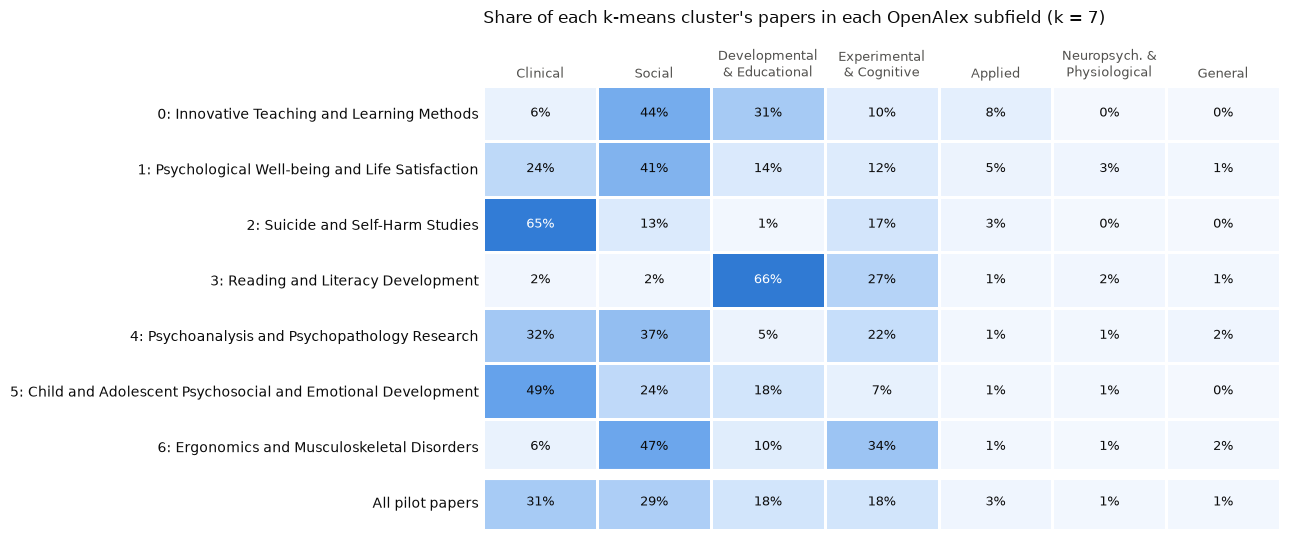

In [62]:
from matplotlib.colors import LinearSegmentedColormap

order = pilot["primary_subfield"].value_counts().index   # subfields from largest to smallest
shares = pd.crosstab(main.labels_, pilot["primary_subfield"], normalize="index").reindex(columns=order, fill_value=0)
shares.loc["All pilot papers"] = pilot["primary_subfield"].value_counts(normalize=True).reindex(order)   # reference row

short = {"Clinical Psychology": "Clinical", "Social Psychology": "Social",
         "Developmental and Educational Psychology": "Developmental\n& Educational",
         "Experimental and Cognitive Psychology": "Experimental\n& Cognitive", "Applied Psychology": "Applied",
         "Neuropsychology and Physiological Psychology": "Neuropsych. &\nPhysiological", "General Psychology": "General"}
rows = [f"{k}: {summary.at[k, 'topic 1']}" for k in range(K)] + ["All pilot papers"]
BLUES = LinearSegmentedColormap.from_list("blues", ["#f4f8fe", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.pcolormesh(shares.to_numpy(), cmap=BLUES, vmin=0, vmax=1, edgecolors="white", linewidth=2)
for i in range(shares.shape[0]):
    for j in range(shares.shape[1]):
        value = shares.iat[i, j]
        ax.text(j + 0.5, i + 0.5, f"{value:.0%}", ha="center", va="center", fontsize=9,
                color="white" if value > 0.5 else INK)
ax.invert_yaxis()
ax.set_xticks(np.arange(len(order)) + 0.5, [short[s] for s in order], color=MUTED, fontsize=9)
ax.set_yticks(np.arange(len(rows)) + 0.5, rows, color=INK)
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.axhline(K, color="white", linewidth=8)   # gap before the reference row
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Share of each k-means cluster's papers in each OpenAlex subfield (k = 7)", color=INK, loc="left", pad=45)
fig.tight_layout()
fig.savefig(FIGURES / "cluster_subfield_shares.png", dpi=200, bbox_inches="tight")
plt.show()

Most clusters do not follow OpenAlex's subfield boundaries, however the clusters are semantically coherent. This explains the low NMI.

### t-SNE map (k = 7)

A picture only: t-SNE keeps each paper's nearest neighbours close, but the distances between groups and the sizes of groups are not meaningful. The clusters come from k-means on the full 768-dimensional vectors; t-SNE just places them on a page.

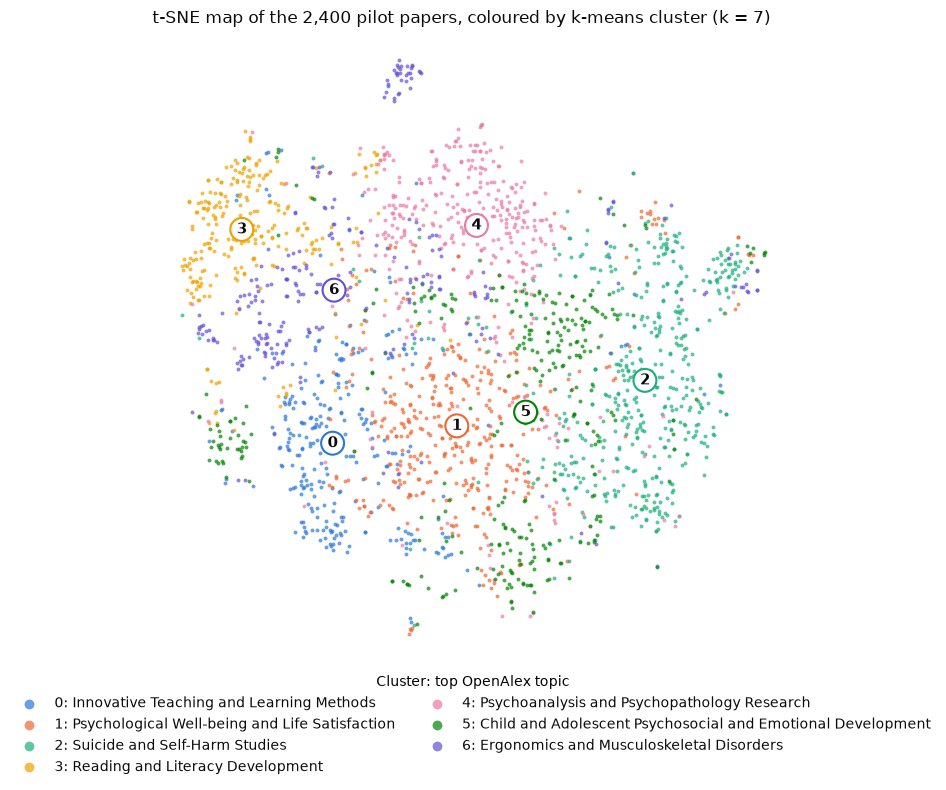

In [58]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

reduced = PCA(n_components=50, random_state=SEED).fit_transform(specter)   # 50 dimensions keep about 70% of the variance
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(reduced)

CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
fig, ax = plt.subplots(figsize=(9, 8))
for k in range(K):
    members = main.labels_ == k
    ax.scatter(xy[members, 0], xy[members, 1], s=8, color=CLUSTER_COLORS[k], alpha=0.7, linewidths=0,
               label=f"{k}: {summary.at[k, 'topic 1']}")
    cx, cy = np.median(xy[members], axis=0)   # label each cluster at its centre, so colour is not the only cue
    ax.annotate(str(k), (cx, cy), ha="center", va="center", fontsize=11, fontweight="bold", color=INK,
                bbox=dict(boxstyle="circle,pad=0.25", fc="white", ec=CLUSTER_COLORS[k], lw=1.5))
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("t-SNE map of the 2,400 pilot papers, coloured by k-means cluster (k = 7)", color=INK, loc="left")
ax.legend(frameon=False, labelcolor=INK, markerscale=2.5, loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2,
          title="Cluster: top OpenAlex topic")
fig.tight_layout()
fig.savefig(FIGURES / "tsne_k7.png", dpi=200, bbox_inches="tight")
plt.show()

### Elbow plot (k = 2–30)

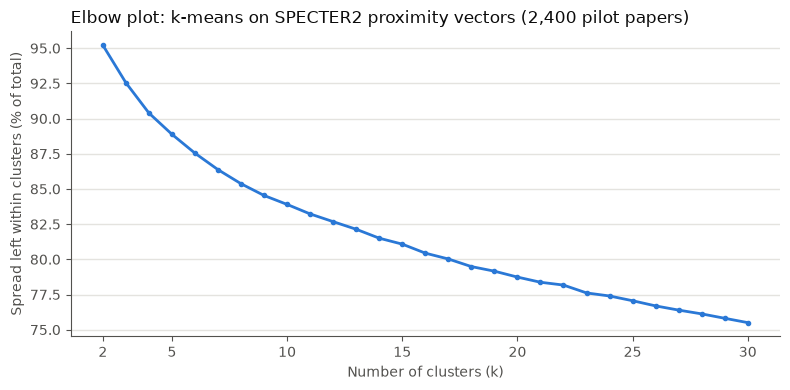

2     95.2
5     88.9
10    83.9
15    81.1
20    78.7
25    77.1
30    75.5
dtype: float64

In [56]:
ks = range(2, 31)
total = ((specter - specter.mean(axis=0)) ** 2).sum()   # spread around the overall mean (k = 1)
elbow, cluster_labels = {}, {}
for k in ks:
    fit = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(specter)
    elbow[k] = float(fit.inertia_ / total)
    cluster_labels[k] = fit.labels_          # reused by the silhouette cell
elbow = pd.Series(elbow)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(elbow.index, elbow * 100, color=COLORS[0], linewidth=2, marker="o", markersize=3)
ax.set_xticks([2, 5, 10, 15, 20, 25, 30])
ax.set_xlabel("Number of clusters (k)", color=MUTED)
ax.set_ylabel("Spread left within clusters (% of total)", color=MUTED)
ax.set_title("Elbow plot: k-means on SPECTER2 proximity vectors (2,400 pilot papers)", color=INK, loc="left")
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "kmeans_elbow.png", dpi=200)
plt.show()

elbow.mul(100).round(1).loc[[2, 5, 10, 15, 20, 25, 30]]

Elbow plot shows no clear elbow. 

### Silhouette score (k = 2–30)

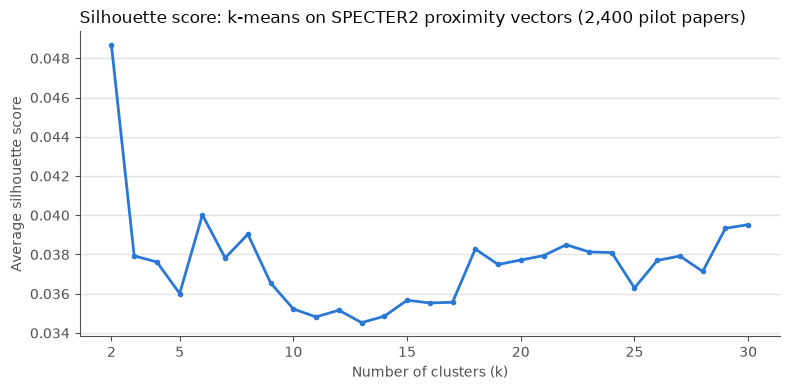

2     0.049
3     0.038
4     0.038
5     0.036
7     0.038
10    0.035
15    0.036
20    0.038
25    0.036
30    0.040
dtype: float64

In [57]:
from sklearn.metrics import silhouette_score

# per paper: (b - a) / max(a, b), with a = mean distance to its own cluster, b = mean distance to the nearest other cluster
silhouette = pd.Series({k: silhouette_score(specter, labels, metric="euclidean")
                        for k, labels in cluster_labels.items()})

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(silhouette.index, silhouette, color=COLORS[0], linewidth=2, marker="o", markersize=3)
ax.set_xticks([2, 5, 10, 15, 20, 25, 30])
ax.set_xlabel("Number of clusters (k)", color=MUTED)
ax.set_ylabel("Average silhouette score", color=MUTED)
ax.set_title("Silhouette score: k-means on SPECTER2 proximity vectors (2,400 pilot papers)", color=INK, loc="left")
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "kmeans_silhouette.png", dpi=200)
plt.show()

silhouette.round(3).loc[[2, 3, 4, 5, 7, 10, 15, 20, 25, 30]]

Silhouette scores are all low.

## Summary of the exploration

Before embedding all 240,000 papers, I tested the measuring instrument on the full pool and on a pilot of 2,400 papers (100 per year). The truncation count was quick, since it needs only the tokenizer. The model check took the longest: 106 OpenAlex requests found a cited work with an abstract for 1,676 of the pilot papers, and then I embedded the pilot with three models.

I started from SPECTER2 with the proximity adapter because it is the model Hao et al. (2026) used to define KE. Since I am replicating their measure in one field over time, keeping their model means my KE is the same measure they published. The model check was meant to confirm that this choice also works for Psychology, not to search for the best model. All three models performed well: each placed a paper's cited work closer than a random same-year paper about 95% of the time (AUC 0.947 for bge-base, 0.952 for SPECTER2 base, and 0.958 for SPECTER2 proximity), far above the 0.5 expected by chance, and cosine and Euclidean distance gave almost the same scores. The differences between models are small and the test favours SPECTER2, so the results gave no reason to depart from Hao et al.'s model, and I kept SPECTER2 proximity.

Clustering was the most open-ended part. The usual diagnostics did not point to a number of clusters, so I relied on reading each cluster's topics.

## What I learned and next steps

**What I learned**

- **The instrument has to treat every year alike.** Hao et al.'s 288-token cutoff would truncate 18% of inputs in 2001 but 46% in 2024, because abstracts get longer. At 512 tokens the share is 4–7% in every year, so I use 512.
- **SPECTER2 proximity works as well for early papers as for recent ones.** Its citation-test score (0.958) barely changes between 2001–2008 and 2017–2024 (−0.006). Year-to-year KE comparisons rely on this: the model should not track relatedness better in some years than in others.
- **Psychology's semantic space is a continuum.** Silhouette scores stay between 0.035 and 0.049 for every k from 2 to 30, and the elbow plot has no bend, so any k divides a continuous space rather than finding natural groups. The k = 7 clusters are still coherent topics (for example reading, language and phonetics), except cluster 6, which joins ergonomics with primate behaviour.
- **Clusters follow subject matter, not OpenAlex subfields** (NMI 0.16). The reading cluster is 66% Developmental and Educational, but the teaching and teamwork cluster splits 44% Social and 31% Developmental and Educational. Since my composition analysis is about themes, I use the clusters.

**Choice: k = 7.** With no guidance from the elbow or silhouette plots, I chose k for interpretability: seven clusters are coherent, reasonably balanced (253 to 497 pilot papers each), and easy to compare with the seven subfields. I chose it before computing any KE, so it does not depend on the growth–KE pattern.

**Next steps**

1. Embed all 240,000 papers with the setup tested here (`src/embeddings.py`) and save the vectors by year.
2. Check vector norms by year and fix the rule for duplicate abstracts.
3. Compute annual KE (1,000 draws of 1,000 papers per year) and read the papers that set the maximum distance.
4. Refit k = 7 on an equal number of papers per year, check that the clusters are stable across random starts, and name a smaller and a larger k as robustness checks before any composition results.
5. Compute composition-standardized KE and regress Δlog KE on Δlog publication count.